# Example: Static forward free-boundary equilibrium calculations (in MAST)

---

Here we will generate an equilibrium (solve for the plasma flux with fixed coil currents) on MAST, the predecessor of MAST-U. The machine geometry (active coils, passive structures and wall) comes from the public [FAIR-MAST](https://mastapp.site) database.

The coil currents, passive structure currents and profiles are those of the EFIT reconstruction of MAST shot 30421 at 0.25 s. They are stored in `data/MAST_30421_0.25s.json`, together with the EFIT boundary for comparison.

### Import packages

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np

### Create the machine object

In [2]:
# build machine
from freegsnke import build_machine

tokamak = build_machine.tokamak(
    active_coils_path="../machine_configs/MAST/MAST_active_coils.pickle",
    passive_coils_path="../machine_configs/MAST/MAST_passive_coils.pickle",
    limiter_path="../machine_configs/MAST/MAST_limiter.pickle",
    wall_path="../machine_configs/MAST/MAST_wall.pickle",
)

/Users/rt2549/projects/freegsnke/freegsnke/parallel.py:662: UserWarning: Estimated ideal maximum threadcount None is greater than numexpr maximum. Consider setting environment variable NUMEXPR_MAX_THREADS to None
  warnings.warn(


Active coils --> built from pickle file.
Passive structures --> built from pickle file.
Limiter --> built from pickle file.
Wall --> built from pickle file.
Magnetic probes --> none provided.
Resistance (R) and inductance (M) matrices --> built using actives (and passives if present).
Tokamak built.


Text(0, 0.5, 'Height, $Z$ [m]')

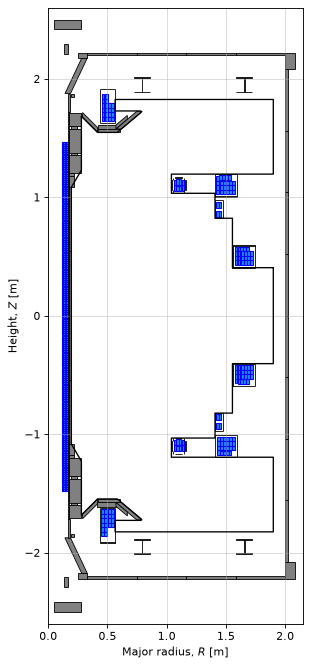

In [3]:
# plot the machine
fig, ax = plt.subplots(figsize=(6, 10), dpi=80)

tokamak.plot(axis=ax, show=False)  # plots the active coils and passive structures
ax.plot(tokamak.limiter.R, tokamak.limiter.Z, "k-", linewidth=1.2)  # plots the limiter
ax.grid(alpha=0.5)
ax.set_aspect("equal")
ax.set_xlim(0.0, 2.15)
ax.set_ylim(-2.6, 2.6)
ax.set_xlabel(r"Major radius, $R$ [m]")
ax.set_ylabel(r"Height, $Z$ [m]")

### Instantiate an equilibrium

In [4]:
from freegsnke import equilibrium_update

eq = equilibrium_update.Equilibrium(
    tokamak=tokamak,       # provide tokamak object
    Rmin=0.06, Rmax=1.98,  # radial range (same as the EFIT grid)
    Zmin=-2.0, Zmax=2.0,   # vertical range (same as the EFIT grid)
    nx=129,                # number of radial grid points (needs to be of the form 2**n + 1)
    ny=129,                # number of vertical grid points (needs to be of the form 2**n + 1)
)

### Load the EFIT data and instantiate a profile object

In [5]:
# EFIT reconstruction of MAST shot 30421 at 0.25 s
with open("data/MAST_30421_0.25s.json") as f:
    efit = json.load(f)

from freegsnke.jtor_update import GeneralPprimeFFprime

profiles = GeneralPprimeFFprime(
    eq=eq,                                     # equilibrium object
    Ip=efit["Ip"],                             # plasma current [A]
    fvac=efit["fvac"],                         # fvac = R * B_tor [T m]
    psi_n=np.array(efit["psi_n"]),             # normalised poloidal flux
    pprime_data=np.array(efit["pprime"]),      # pressure derivative profile
    ffprime_data=np.array(efit["ffprime"]),    # FF' profile
    p_data=np.array(efit["pressure"]),         # pressure profile (optional)
    f_data=np.array(efit["f"]),                # F profile (optional)
    Ip_logic=True,
)

### Set the coil currents

EFIT gives one current for each circuit. We convert these currents to FreeGSNKE coil currents as follows:
- The shaping coil currents (P2 to P6) are in ampere-turns, so we divide them by the number of turns in each coil.
- The solenoid (SOL) current is multiplied by 0.5 because of its wiring.
- Each PF coil case is one EFIT circuit, but it is made of a number of separate elements in FreeGSNKE. We split the case current across these elements in proportion to their areas.
- All other passive structure currents are used as they are.

In [6]:
currents = efit["currents"]

# active coils
for name in efit["actives_order"]:
    if name == "SOL":
        value = 0.5 * currents[name]
    else:
        value = currents[name] / len(tokamak.coils_dict[name]["coords"][0])
    tokamak.set_coil_current(coil_label=name, current_value=value)

# passive structures
for name in efit["passives_order"]:
    if name.startswith("coil_cases"):
        case = "coil_cases_" + name[-3:]  # e.g. "coil_cases_P2U"
        elements = [c for c in tokamak.coil_names if case in c]
        areas = np.array([tokamak.coils_dict[e]["dR"] * tokamak.coils_dict[e]["dZ"] for e in elements])
        for element, area in zip(elements, areas):
            tokamak.set_coil_current(coil_label=element, current_value=currents[name] * area / areas.sum())
    else:
        tokamak.set_coil_current(coil_label=name, current_value=currents[name])

### The forward solve

In [7]:
# load the static nonlinear solver
from freegsnke import GSstaticsolver
from freegsnke.equilibrium import PsiGuessParabolicJtor

GSStaticSolver = GSstaticsolver.NKGSsolver(eq, seed=42)

# put the initial guess near the EFIT magnetic axis (below the midplane),
# so that the solver finds the lower X-point configuration
psi_guess = PsiGuessParabolicJtor(
    h=efit["axis"][0],  # radial centre of ellipse
    k=efit["axis"][1],  # vertical centre of ellipse
    a=0.5,              # approximate radial minor radius of the plasma
    b=0.9,              # approximate vertical minor radius of the plasma
    Ip=profiles.Ip,     # plasma current used to scale the guess
    psi_scale=1.0,      # scaling factor for the initial flux guess
)
eq.plasma_psi = psi_guess(eq=eq)

# carry out the forward solve with fixed coil currents
GSStaticSolver.forward_solve(
    eq=eq,
    profiles=profiles,
    target_relative_tolerance=1e-7,
    max_solving_iterations=100,
    verbose=True,  # print output
)

-----
Forward static solve starting...
Initial guess for plasma_psi successful, residual found.
Initial relative error = 6.18e-01
-----
Forward static solve starting...
Initial guess for plasma_psi successful, residual found.
Initial relative error = 6.18e-01
-----
Picard iteration: 0
Update too large, resized.
...relative error =  4.09e-01
-----
Picard iteration: 1
Update too large, resized.
...relative error =  2.37e-01
-----
Picard iteration: 2
...relative error =  9.68e-02
-----
-----
Newton-Krylov iteration: 3
...number of Krylov vectors used =  2
...relative error =  1.54e-02
-----
-----
Newton-Krylov iteration: 4
...number of Krylov vectors used =  2
...relative error =  4.70e-03
-----
-----
Newton-Krylov iteration: 5
...number of Krylov vectors used =  3
...relative error =  9.67e-04
-----
-----
Newton-Krylov iteration: 6
...number of Krylov vectors used =  17
Increase in residual, update reduction triggered.
...relative error =  7.89e-04
-----
-----
Newton-Krylov iteration: 7


### Plot the equilibrium and compare with EFIT

Text(0, 0.5, 'Height, $Z$ [m]')

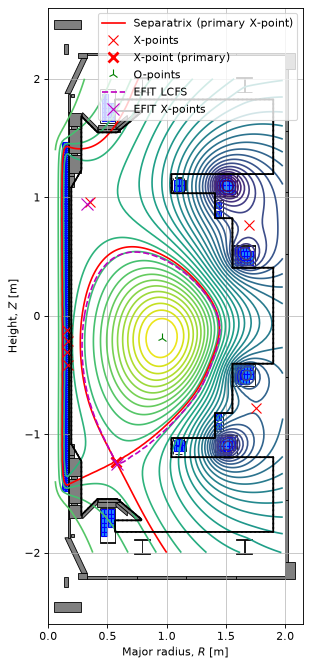

In [8]:
efit_lcfs = np.array(efit["lcfs"])
efit_xpoints = np.array(efit["xpoints"])

fig, ax = plt.subplots(figsize=(6, 10), dpi=80)

ax.grid(zorder=0, alpha=0.75)
ax.set_aspect("equal")
eq.tokamak.plot(axis=ax, show=False)  # plots the active coils and passive structures
eq.plot(axis=ax, show=False)          # plots the equilibrium
ax.plot(tokamak.limiter.R, tokamak.limiter.Z, "k-", linewidth=1.2)  # plots the limiter
ax.plot(efit_lcfs[:, 0], efit_lcfs[:, 1], "m--", linewidth=1.5, label="EFIT LCFS")
ax.plot(efit_xpoints[:, 0], efit_xpoints[:, 1], "mx", markersize=10, label="EFIT X-points")
ax.legend(loc="upper right")
ax.set_xlim(0.0, 2.15)
ax.set_ylim(-2.6, 2.6)
ax.set_xlabel(r"Major radius, $R$ [m]")
ax.set_ylabel(r"Height, $Z$ [m]")

In [9]:
print(f"Plasma current: FreeGSNKE = {eq.plasmaCurrent():.4e} A, EFIT = {efit['Ip']:.4e} A")
print(f"Magnetic axis : FreeGSNKE = ({eq.opt[0, 0]:.3f}, {eq.opt[0, 1]:.3f}) m, EFIT = ({efit['axis'][0]:.3f}, {efit['axis'][1]:.3f}) m")
print(f"Lower X-point : FreeGSNKE = ({eq.xpt[0, 0]:.3f}, {eq.xpt[0, 1]:.3f}) m, EFIT = ({efit_xpoints[0, 0]:.3f}, {efit_xpoints[0, 1]:.3f}) m")

Plasma current: FreeGSNKE = 6.4084e+05 A, EFIT = 6.4084e+05 A
Magnetic axis : FreeGSNKE = (0.959, -0.187) m, EFIT = (0.965, -0.216) m
Lower X-point : FreeGSNKE = (0.570, -1.231) m, EFIT = (0.583, -1.256) m
